# PakFreight — Week 2 assignment

Python notebook edition. The source evidence is retained unchanged in `data/`. Tasks 1–5 are answered here and in the notebook. The original activity workbook has separate classroom task numbering (T1–T7); those tabs are completed too. Student name and roll number can be entered before submission.

**Submission limitation:** The Python pipeline is executed and validated. Power Query M and DAX are supplied for Power BI, but no Power BI session was available: a genuine PBIX and Applied Steps/report screenshots are still required by the original rubric. Python plots are labelled as Python evidence and are not Power BI screenshots.


**Run instructions:** extract the ZIP, install `requirements.txt`, open this notebook and Run All. All files resolve relative to this notebook folder. The executed outputs below are from the supplied February 2026 data.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import display, Markdown
BASE = Path.cwd()
if not (BASE / 'data' / 'marine_shipments.csv').exists():
    raise FileNotFoundError('Open the notebook from the extracted assignment folder, with data/ beside it.')
plt.rcParams.update({'figure.dpi': 130, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
print('PakFreight — Week 2 | February 2026')


PakFreight — Week 2 | February 2026


## Task 1 — Tiers and warehouse properties

| Tier | Job | PakFreight example | Must not happen |
|---|---|---|---|
| Staging | Preserve evidence and apply repeatable quality transformations | Parse marine dates with UK locale; convert rail tonnes to kg; reject road junk | Business users must not aggregate unclean source queries |
| Storage | Hold consistent integrated records and history | Store one row per shipment with common IDs, units and source identity | Overwrite historical dimension values without preserving versions |
| Presentation | Expose agreed measures and dimensional views | Show total weight and breakdown by transport mode | Apply a second rail unit conversion in a visual |

| Inmon property | Satisfied in PakFreight | Broken example |
|---|---|---|
| Subject-oriented | Organise all modes around the shipment business subject | Separate file-shaped reports with no shared shipment definition |
| Integrated | Same eight columns, kg unit, ID prefixes and canonical statuses | Interpret 32.5 rail tonnes as 32.5 kg |
| Time-variant | Retain dated shipments and effective-dated customer/route history | Replace old addresses so historical routes appear to use today's address |
| Non-volatile | Retain loaded facts; record corrections with an audit trail | Delete or overwrite yesterday's freight facts to hide an error |

| Requirement | Choice and reason |
|---|---|
| Truck positions every two minutes | ODS: current operational state with frequent updates |
| CFO cost per tonne-km over three years | EDW: consistent historical comparison; distance is additional required data |
| Did 45017 leave today? | ODS: current dispatch event/status; this February sample cannot answer today's question |
| Mode profitability since 2023 | EDW: historical costs and revenues; billing revenue is not in these files |

The notebook draws an independent arrangement in which each department loads its own file directly into its mart, and a dependent arrangement in which all sources pass through staging and one integrated warehouse before departmental marts. Independent marts apply local rules to inconsistent units and row definitions. Operations counts an aggregate row, Finance misreads the rail unit, and Sales counts a trip twice. A shared warehouse and conformed definitions make all three use the same accepted facts.

Raw files pass through staging so quality, schema and unit problems are detected and recorded before they affect shared measures.

**Address question:** Losing an old customer address principally breaks time variance and also conflicts with non-volatility if existing history is destructively changed. A type-2 slowly changing Customer dimension should retain the old version, add the new version with effective dates and a surrogate key, and keep historical facts linked to the appropriate version.


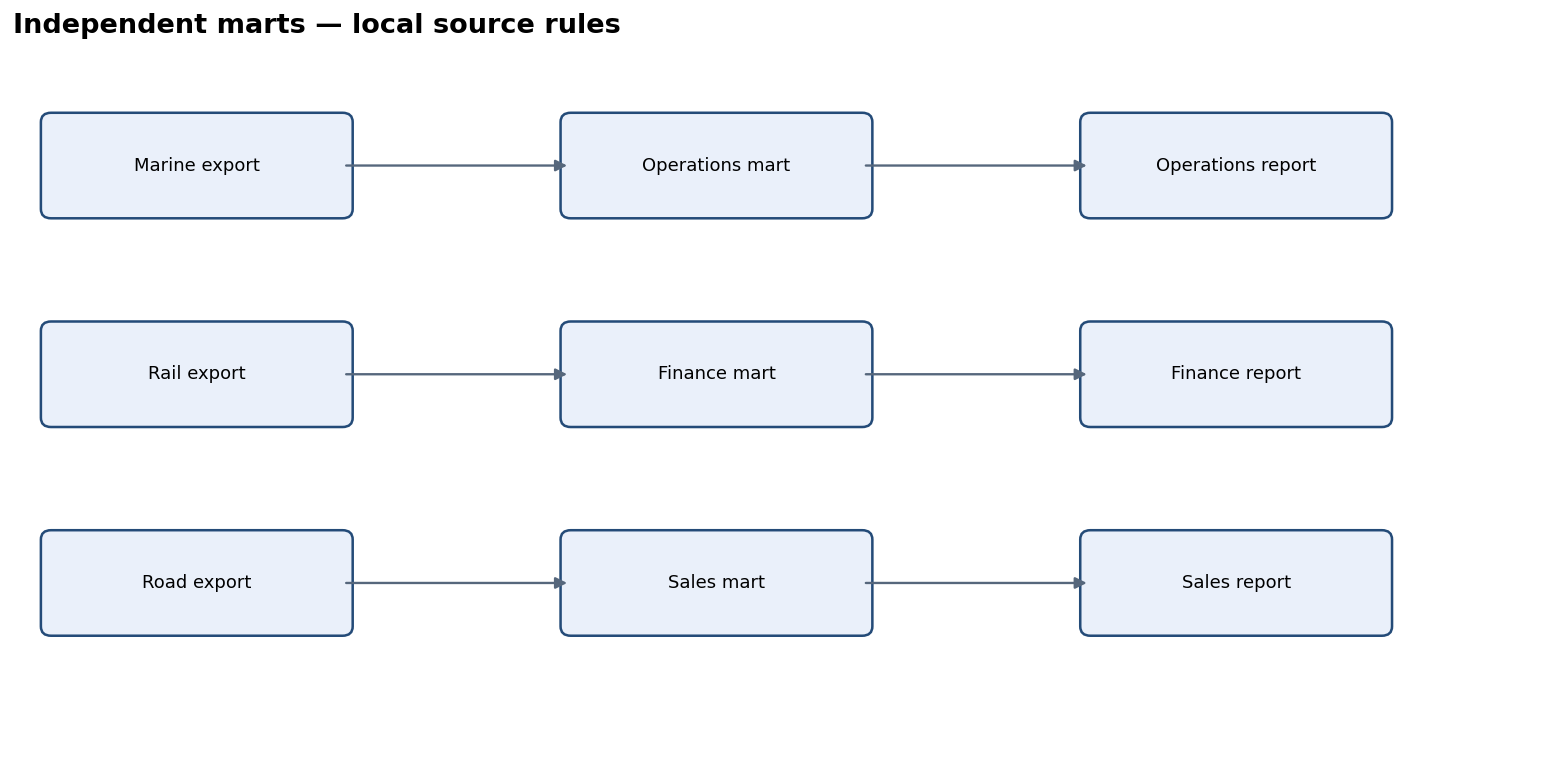

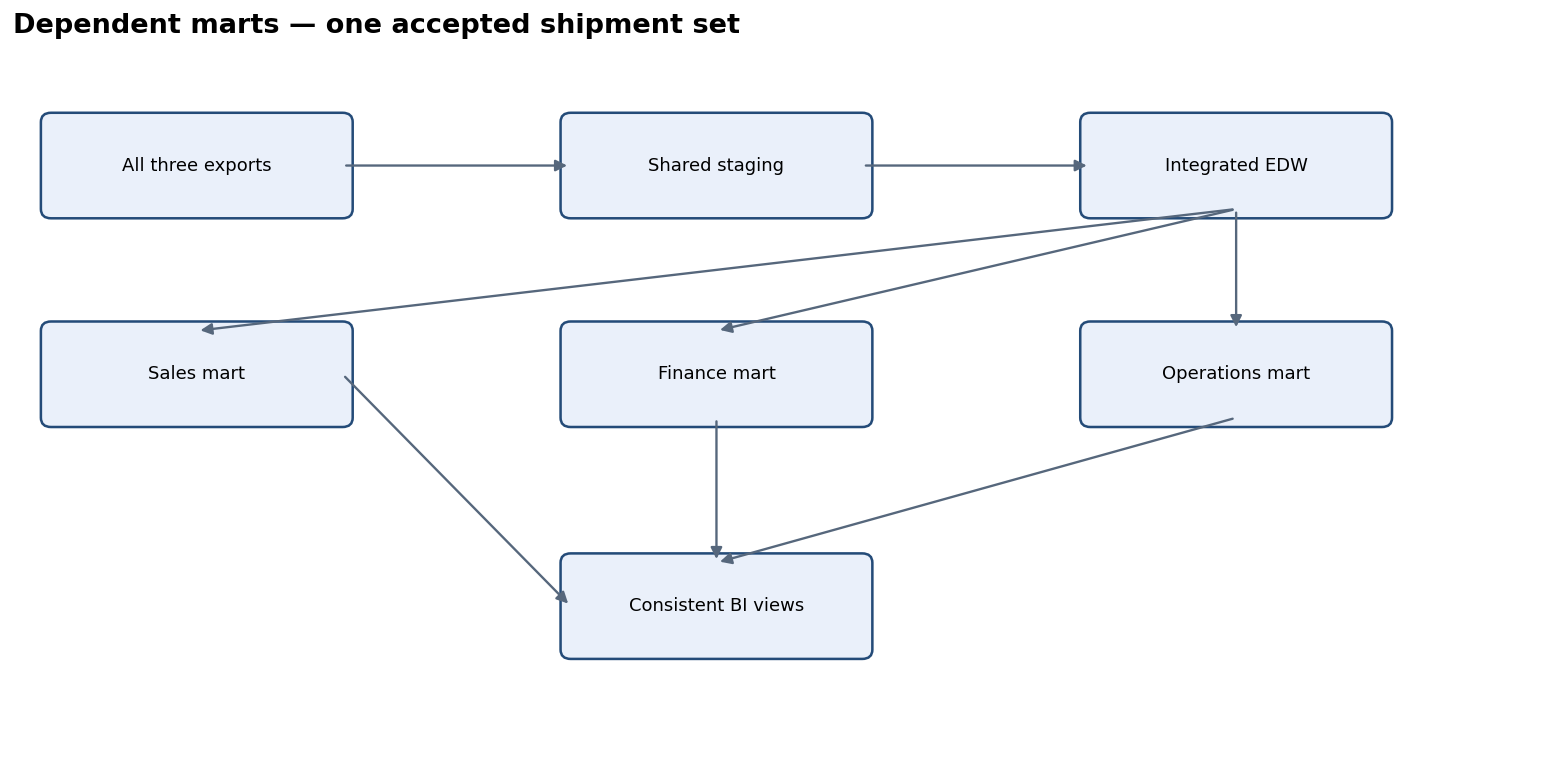

In [2]:
def diagram(title, boxes, edges, filename):
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.set(xlim=(0,12), ylim=(0,6)); ax.axis('off')
    ax.set_title(title, loc='left', fontweight='bold', fontsize=15, pad=14)
    for key,(x,y,label) in boxes.items():
        box=FancyBboxPatch((x,y),2.3,0.75,boxstyle='round,pad=0.08',
                           facecolor='#eaf0fa',edgecolor='#244b78',linewidth=1.4)
        ax.add_patch(box);ax.text(x+1.15,y+0.375,label,ha='center',va='center',fontsize=10)
    for a,b in edges:
        xa,ya,_=boxes[a];xb,yb,_=boxes[b]
        if xb > xa+2.3: start,end=(xa+2.3,ya+0.375),(xb,yb+0.375)
        else: start,end=(xa+1.15,ya),(xb+1.15,yb+0.75)
        ax.add_patch(FancyArrowPatch(start,end,arrowstyle='-|>',mutation_scale=13,color='#56677c',linewidth=1.3))
    fig.tight_layout();fig.savefig(BASE/'results'/filename,bbox_inches='tight');plt.show()

diagram('Independent marts — local source rules',
 {'m':(0.3,4.7,'Marine export'),'r':(0.3,2.9,'Rail export'),'d':(0.3,1.1,'Road export'),
  'o':(4.4,4.7,'Operations mart'),'f':(4.4,2.9,'Finance mart'),'s':(4.4,1.1,'Sales mart'),
  'or':(8.5,4.7,'Operations report'),'fr':(8.5,2.9,'Finance report'),'sr':(8.5,1.1,'Sales report')},
 [('m','o'),('r','f'),('d','s'),('o','or'),('f','fr'),('s','sr')], 'independent_marts.png')
diagram('Dependent marts — one accepted shipment set',
 {'src':(0.3,4.7,'All three exports'),'stg':(4.4,4.7,'Shared staging'),'edw':(8.5,4.7,'Integrated EDW'),
  'ops':(8.5,2.9,'Operations mart'),'fin':(4.4,2.9,'Finance mart'),'sales':(0.3,2.9,'Sales mart'),
  'bi':(4.4,0.9,'Consistent BI views')},
 [('src','stg'),('stg','edw'),('edw','ops'),('edw','fin'),('edw','sales'),('ops','bi'),('fin','bi'),('sales','bi')], 'dependent_marts.png')


## Task 2 — Architecture and lifecycle

| Dimension | Inmon | Kimball |
|---|---|---|
| Starting point | Enterprise requirements and integrated core | Prioritised business process and enterprise bus plan |
| Core modelling | Normalised enterprise warehouse, usually 3NF | Dimensional facts and dimensions |
| First value | Usually slower due to broad integration | Earlier through one useful process mart |
| Main risk | Long initial delivery and expensive enterprise modelling | Inconsistent marts if conformance is ignored |
| Consistency | Enterprise model feeding dependent marts | Conformed dimensions and shared fact definitions |
| Delivery | Core warehouse followed by derived marts | Incremental process stars tied through the bus |

Original diagrams in the notebook show CIF (sources, staging, normalised EDW, dependent marts, reports) and Bus (sources, staging, process facts and shared dimensions). Neither architecture makes staging optional.

| Scenario | Choice | Reason |
|---|---|---|
| 1 Bank agrees enterprise customer first | Inmon | Enterprise definition precedes reporting |
| 2 Startup dashboard within six weeks | Kimball | A small process star delivers early |
| 3 Hospital, five systems, regulatory programme | Inmon | Integrated enterprise history supports regulatory consistency |
| 4 Shipments first, conformed Date and Route | Kimball | Process-first incremental delivery with conformance |
| 5 Normalised core feeding departmental marts | Inmon | Dependent marts derive from the EDW |
| 6 Telecom bronze/silver/gold lakehouse | Hybrid | Integrated layers support dimensional serving; layering alone is not decisive |
| 7 Census model agreed before loading | Inmon | Enterprise model is defined up front |
| 8 Returns reuses Product | Kimball | New process reuses a conformed dimension |
| 9 Six irreconcilable marts | Hybrid | Retain useful stars while integrating definitions/core; disconnected marts alone are not Kimball |
| 10 Bank integrates acquired competitor | Inmon | Enterprise customer/account integration is the stated priority; dimensional consumption may follow |

### Kimball lifecycle: Shipments iteration

1. Programme planning: scope iteration 1 to February shipments, name owners and agree 34 accepted records and weight reconciliation as acceptance criteria.
2. Business requirements: define shipment grain as one unique mode-prefixed shipment; agree canonical status and kg as the common unit.
3. Technical architecture: immutable file sources feed staging transformations, integrated storage and a presentation model.
4. Product selection: choose Power BI Desktop for required delivery and Python/Jupyter for reproducible profiling and independent checks.
5. Dimensional modelling: plan FactShipment and shared Date/Route dimensions; SourceSystem identifies mode. This week's eight-column table precedes the full star.
6. Physical design: select typed columns and stable shipment keys; plan surrogate keys and indexes in a database implementation.
7. ETL development: parse dates, multiply rail weights by 1,000, canonicalise text, quarantine road removals and append.
8. BI development: create weight and shipment-count measures, mode bar chart and status counts.
9. Deployment: validate row counts, totals, date traps and staging load settings before publishing.
10. Maintenance: monitor refresh failures, unit contracts, duplicate exceptions and export schema changes.

Iteration 2 Billing should reuse **Date and Route**. Conformed means their keys, attribute meanings and hierarchies are agreed and shared across shipment and billing stars; different event dates use the same Date dimension in different roles. Customer is another useful conformed dimension, but its keys need a new authoritative source because these files do not provide customer identity.

SDLC begins with requirements and builds a program to meet them. CLDS begins by examining available data, then refines realistic requirements through profiling and feedback. For example, the rail header reveals the tonne unit, and the road file reveals that physical lines are not shipment counts. This is an iterative discovery emphasis, not a rule that Kimball ignores requirements or Inmon never examines data.

**Architecture question:** Shipments first with conformed dimensions is bottom-up Kimball. For a top-down interpretation, an enterprise integrated normalised core would already have been designed and built, and the Shipments mart would be derived from it.


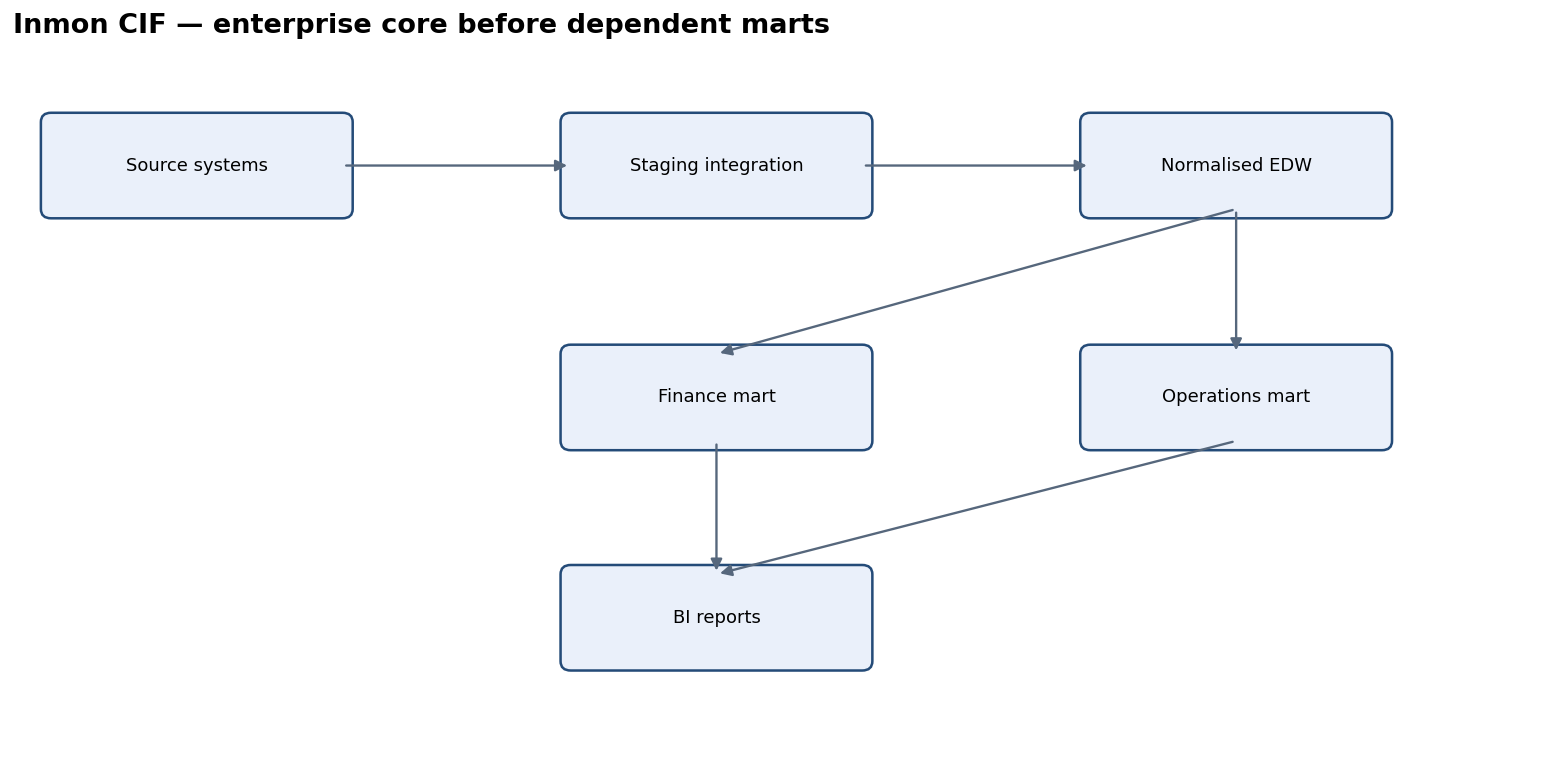

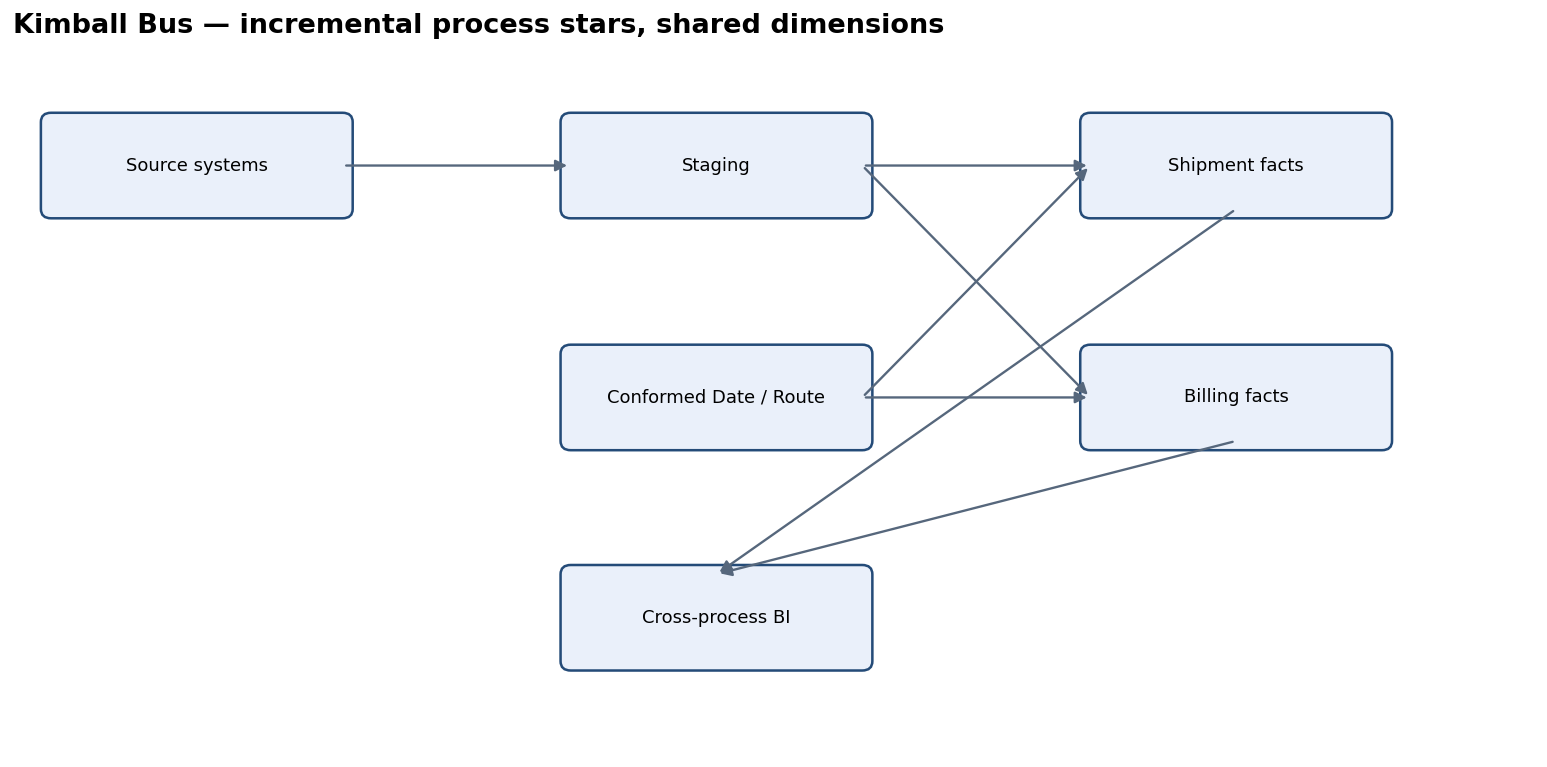

In [3]:
diagram('Inmon CIF — enterprise core before dependent marts',
 {'src':(0.3,4.7,'Source systems'),'stg':(4.4,4.7,'Staging integration'),'core':(8.5,4.7,'Normalised EDW'),
  'ops':(8.5,2.7,'Operations mart'),'fin':(4.4,2.7,'Finance mart'),'bi':(4.4,0.8,'BI reports')},
 [('src','stg'),('stg','core'),('core','ops'),('core','fin'),('ops','bi'),('fin','bi')], 'inmon_cif.png')
diagram('Kimball Bus — incremental process stars, shared dimensions',
 {'src':(0.3,4.7,'Source systems'),'stg':(4.4,4.7,'Staging'),
  'sh':(8.5,4.7,'Shipment facts'),'bill':(8.5,2.7,'Billing facts'),
  'dim':(4.4,2.7,'Conformed Date / Route'),'bi':(4.4,0.8,'Cross-process BI')},
 [('src','stg'),('stg','sh'),('stg','bill'),('dim','sh'),('dim','bill'),('sh','bi'),('bill','bi')], 'kimball_bus.png')


## Task 3 — Data Detective and reconciliation

The completed activity workbook records 12 issues with examples and impacts. Marine has text dates, uppercase statuses and hidden spaces. Rail has two title rows, a tonnes unit, numeric identifiers and mixed-case/space-padded statuses. Road has lowercase IDs, ISO text dates, a duplicate, an empty record and a non-data TOTAL record with missing mandatory fields. No real shipment has a missing mandatory date, ID or weight; the missing values belong to junk rows. Different location types are retained as supplied: Karachi Port and Karachi Cantt must not be merged merely because both are in Karachi.

### Exact stovepipe arithmetic

| Department | Arithmetic in kg | Tonnes | Error |
|---|---|---|---|
| Operations | 206,500 + 295,250 + (166,000 − 6,100) = 661,650 | 661.65 | Removes the duplicate but keeps road TOTAL = 83,000 kg |
| Finance | 206,500 + 295.25 + 76,900 = 283,695.25 | 283.69525 → 283.70 | Rail tonnes treated as kg; display rounded to two decimals |
| Sales | 206,500 + 295,250 + 83,000 = 584,750 | 584.75 | Keeps the second 6,100 kg trip after removing TOTAL |
| Shared staging | 206,500 + 295,250 + 76,900 = 578,650 | 578.65 | Correct grain, units and filtering |

Each department used internally consistent rules and obtained a plausible sum from its local file. They believed the totals because they had no shared unit, shipment-grain definition or cross-source reconciliation.

| Source | Raw records | Removed | Loaded | Weight kg |
|---|---:|---:|---:|---:|
| Marine | 12 | 0 | 12 | 206,500 |
| Rail | 10 | 0 | 10 | 295,250 |
| Road | 15 | 3 | 12 | 76,900 |
| Total | 37 | 3 | 34 | 578,650 |

### Named exclusions and lineage

1. `marine_shipments.csv`: header on physical line 1; data lines 2–13. Rename columns, parse every date as dd/mm/yyyy, trim/proper-case status, retain kg and add Marine. Keep all 12 records.
2. `rail_shipments.xlsx`, sheet Rail: remove title rows 1–2, promote row 3, load worksheet rows 4–13. Rename columns, parse native Excel dates, prefix IDs with RL-, multiply each of 10 tonne values by 1,000, trim/proper-case status and add Rail.
3. `road_shipments.csv`: header line 1; records lines 2–16. Uppercase IDs; remove physical line **15**, the all-empty record; remove line **16**, `TOTAL` (83,000 kg), because it summarises rows and has no shipment date; remove line **7**, the repeated `rd-505` (6,100 kg), retaining its identical first occurrence at line **6**. Parse remaining ISO dates, trim/proper-case status and add Road. Workbook staging equivalents are rows 18, 19 and 10 respectively; original Road_Raw equivalents are rows 15, 16 and 7.
4. Append by common column names into 34 × 8 `Shipments`; preserve source-file and raw-row provenance separately in `results/lineage.csv` so the required eight-column schema stays exact.
5. Sum kg at accepted shipment grain: 206,500 + 295,250 + 76,900 = 578,650. Divide that measure by 1,000 for the displayed 578.65 tonnes. Validate all rows are in February 2026.

The workbook uses formulas for dates, units, IDs, status, Keep flags and rejection reasons; original raw sheets stay intact. Reconciliation checks independently compare derived results to supplied controls.

| Process | Date | Customer | Route | Vehicle | Driver | Station/Port | Commodity |
|---|---|---|---|---|---|---|---|
| Shipments | X | X | X | X | X | X | X |
| Billing & Invoicing | X | X | X |  |  | X | X |
| Fleet Maintenance | X |  |  | X |  | X |  |
| Fuel Purchases | X |  | X | X | X | X |  |
| Driver Trips & Hours | X |  | X | X | X | X |  |
| Customer Complaints | X | X | X |  |  |  | X |

This is a proposed enterprise bus, not a claim that all dimension attributes already exist in the three files. Vehicle, Driver, Customer and Commodity need additional source data. Date appears in every process. Date, Route and Customer should be agreed across Finance, Operations and Sales, along with the shipment-grain/unit rules. Plan the whole bus while delivering one process at a time; build Shipments first for the COO.

**TOTAL control:** Filter/quarantine identifiers equal to TOTAL before modelling, require mandatory shipment keys and dates, and fail validation if aggregate rows survive. Preserve an exclusion log so the control remains auditable.


### Python staging implementation
The following code reads the original exports without modifying them. `_RawRow` identifies a CSV physical line or an Excel worksheet row. Rail units change in staging; discarded Road records are retained in a separate audit output.

In [4]:
"""Repeatable PakFreight staging. Inputs are read-only; outputs retain row lineage."""
from pathlib import Path
import csv
import hashlib
import json
import pandas as pd

CONTRACT = ['ShipmentID','ShipDate','Origin','Destination','WeightKG','CostPKR','Status','SourceSystem']
MAPPING = {
 'Marine': dict(zip(['Shipment_ID','Ship_Date','Origin_Port','Dest_Port','Weight_KG','Cost_PKR','Status'], CONTRACT[:7])),
 'Rail': dict(zip(['Consignment No','Dispatch Date','From Station','To Station','Weight (Tons)','Freight Charges (PKR)','Status'], CONTRACT[:7])),
 'Road': dict(zip(['trip_id','trip_date','from_city','to_city','weight_kg','cost_pkr','status'], CONTRACT[:7]))
}
FILES={'Marine':'marine_shipments.csv','Rail':'rail_shipments.xlsx','Road':'road_shipments.csv'}

def hashes(data_dir):
 return {p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(Path(data_dir).iterdir()) if p.name in FILES.values()}

def load_sources(data_dir):
 data_dir=Path(data_dir)
 raw={}
 for mode, name in FILES.items():
  if mode=='Rail':
   frame=pd.read_excel(data_dir/name, sheet_name='Rail',header=2)
   first_row=4
  else:
   # csv.reader preserves the all-empty road record and its physical line number.
   with (data_dir/name).open(encoding='utf-8',newline='') as f:
    reader=csv.reader(f); header=next(reader); records=list(reader)
   frame=pd.DataFrame(records,columns=header)
   first_row=2
  if set(frame.columns)!=set(MAPPING[mode]):
   raise ValueError(f'{mode}: unexpected schema {list(frame.columns)}')
  frame['_SourceFile']=name
  frame['_RawRow']=range(first_row,first_row+len(frame))
  raw[mode]=frame
 return raw

def stage_sources(raw):
 staged={}; rejected=[]
 for mode, frame in raw.items():
  f=frame.rename(columns=MAPPING[mode]).copy(deep=True)
  if mode=='Road':
   f['ShipmentID']=f['ShipmentID'].fillna('').astype(str).str.strip().str.upper()
   blank=f[CONTRACT[:7]].fillna('').astype(str).apply(lambda col:col.str.strip()).eq('').all(axis=1)
   total=f['ShipmentID'].eq('TOTAL')
   for mask,reason in [(blank,'Blank record: no shipment fields'),(total,'Aggregate TOTAL row: not an individual shipment')]:
    for _,r in f.loc[mask].iterrows():
     rejected.append({'SourceFile':r['_SourceFile'],'RawRow':int(r['_RawRow']),'ShipmentID':r['ShipmentID'],'WeightKG':r['WeightKG'],'Reason':reason})
   f=f.loc[~(blank|total)].copy()
   duplicate=f.duplicated('ShipmentID',keep='first')
   for _,r in f.loc[duplicate].iterrows():
    first=f.loc[f.ShipmentID.eq(r.ShipmentID)].iloc[0]
    if not r[CONTRACT[:7]].equals(first[CONTRACT[:7]]):
     raise ValueError(f'Conflicting duplicate {r.ShipmentID}; requires steward review')
    rejected.append({'SourceFile':r['_SourceFile'],'RawRow':int(r['_RawRow']),'ShipmentID':r['ShipmentID'],'WeightKG':r['WeightKG'],'Reason':f'Identical duplicate; retain raw row {int(first["_RawRow"])}'})
   f=f.loc[~duplicate].copy()
  if mode=='Rail':
   f['ShipmentID']='RL-'+f['ShipmentID'].astype('int64').astype(str)
   f['ShipDate']=pd.to_datetime(f['ShipDate'],errors='raise').dt.normalize()
  else:
   fmt='%d/%m/%Y' if mode=='Marine' else '%Y-%m-%d'
   f['ShipDate']=pd.to_datetime(f['ShipDate'],format=fmt,errors='raise')
  for col in ['Origin','Destination','Status']:
   f[col]=f[col].astype(str).str.strip()
  f['Status']=f['Status'].str.title()
  for col in ['WeightKG','CostPKR']:
   f[col]=pd.to_numeric(f[col],errors='raise')
  if mode=='Rail': f['WeightKG']=f['WeightKG']*1000
  f['SourceSystem']=mode
  staged[mode]=f[CONTRACT+['_SourceFile','_RawRow']]
 lineage=pd.concat(staged.values(),ignore_index=True)
 shipments=lineage[CONTRACT].copy()
 return staged,shipments,lineage,pd.DataFrame(rejected)

def validate(raw,staged,shipments):
 assert shipments.shape==(34,8),shipments.shape
 assert list(shipments)==CONTRACT
 assert not shipments[['ShipmentID','ShipDate','WeightKG']].isna().any().any()
 assert shipments.ShipmentID.str.strip().ne('').all()
 assert shipments.ShipmentID.is_unique
 assert (shipments.WeightKG>0).all()
 assert (shipments.ShipDate.dt.to_period('M')==pd.Period('2026-02')).all()
 totals=shipments.groupby('SourceSystem').WeightKG.sum().to_dict()
 assert totals=={'Marine':206500.0,'Rail':295250.0,'Road':76900.0},totals
 statuses=shipments.Status.value_counts().to_dict()
 assert statuses=={'Delivered':22,'In Transit':8,'Delayed':4},statuses
 dates=shipments.set_index('ShipmentID').ShipDate
 assert dates['MR-1003']==pd.Timestamp('2026-02-03')
 assert dates['MR-1012']==pd.Timestamp('2026-02-13')
 assert shipments.loc[shipments.ShipmentID.eq('RL-45012'),'WeightKG'].iloc[0]==32500
 assert [len(raw[m]) for m in FILES]==[12,10,15]
 assert [len(staged[m]) for m in FILES]==[12,10,12]
 return {'rows':len(shipments),'columns':len(shipments.columns),'total_weight_kg':float(shipments.WeightKG.sum()),'source_weight_kg':totals,'status_counts':statuses,'all_checks_passed':True}

def run(base=None):
 base=Path(base) if base else Path(__file__).resolve().parent
 before=hashes(base/'data'); raw=load_sources(base/'data')
 staged,shipments,lineage,rejected=stage_sources(raw)
 report=validate(raw,staged,shipments)
 assert before==hashes(base/'data'),'Source bytes changed'
 out=base/'results';out.mkdir(exist_ok=True)
 shipments.to_csv(out/'Shipments.csv',index=False,date_format='%Y-%m-%d')
 lineage.to_csv(out/'lineage.csv',index=False,date_format='%Y-%m-%d')
 rejected.to_csv(out/'excluded_rows.csv',index=False)
 report['source_sha256']=before
 (out/'validation.json').write_text(json.dumps(report,indent=2))
 return raw,staged,shipments,lineage,rejected,report



In [5]:
raw, staged, Shipments, lineage, exclusions, validation = run(BASE)
profile = pd.DataFrame([
    {'Source': mode, 'Raw records': len(raw[mode]), 'Removed': len(raw[mode])-len(staged[mode]),
     'Loaded': len(staged[mode]), 'WeightKG': staged[mode].WeightKG.sum()}
    for mode in ['Marine','Rail','Road']
])
display(profile)
print('Total kg:', Shipments.WeightKG.sum())
print('Status counts:', Shipments.Status.value_counts().to_dict())
display(exclusions)


,Source,Raw records,Removed,Loaded,WeightKG
0,Marine,12,0,12,206500.0
1,Rail,10,0,10,295250.0
2,Road,15,3,12,76900.0


,SourceFile,RawRow,ShipmentID,WeightKG,Reason
0,road_shipments.csv,15,,,Blank record: no shipment fields
1,road_shipments.csv,16,TOTAL,83000,Aggregate TOTAL row: not an individual shipment
2,road_shipments.csv,7,RD-505,6100,Identical duplicate; retain raw row 6


Total kg: 578650.0
Status counts: {'Delivered': 22, 'In Transit': 8, 'Delayed': 4}


In [6]:
# Profile missing values before cleaning. Empty strings count as missing.
for mode, frame in raw.items():
    cols=list(MAPPING[mode])
    missing=frame[cols].replace(r'^\s*$', pd.NA, regex=True).isna().sum()
    print('\n'+mode+' — raw columns and missing values')
    display(pd.DataFrame({'dtype': frame[cols].dtypes.astype(str), 'missing': missing}))
    display(frame.head(3))
# Check the two rd-505 records directly against the source evidence.
display(raw['Road'].loc[raw['Road'].trip_id.eq('rd-505')])


,dtype,missing
Shipment_ID,object,0
Ship_Date,object,0
Origin_Port,object,0
Dest_Port,object,0
Weight_KG,object,0
Cost_PKR,object,0
Status,object,0


,Shipment_ID,Ship_Date,Origin_Port,Dest_Port,Weight_KG,Cost_PKR,Status,_SourceFile,_RawRow
0,MR-1001,01/02/2026,Karachi Port,Lahore Dry Port,18000,142000,DELIVERED,marine_shipments.csv,2
1,MR-1002,02/02/2026,Port Qasim,Faisalabad Dry Port,22500,171000,DELIVERED,marine_shipments.csv,3
2,MR-1003,03/02/2026,Karachi Port,Lahore Dry Port,15000,119000,IN TRANSIT,marine_shipments.csv,4


,dtype,missing
Consignment No,int64,0
Dispatch Date,datetime64[ns],0
From Station,object,0
To Station,object,0
Weight (Tons),float64,0
Freight Charges (PKR),int64,0
Status,object,0


,Consignment No,Dispatch Date,From Station,To Station,Weight (Tons),Freight Charges (PKR),Status,_SourceFile,_RawRow
0,45012,2026-02-03,Karachi Cantt,Lahore,32.50,285000,Delivered,rail_shipments.xlsx,4
1,45013,2026-02-03,Karachi Cantt,Rawalpindi,28.75,301000,delivered,rail_shipments.xlsx,5
2,45014,2026-02-04,Pipri Marshalling Yard,Faisalabad,30.00,262000,In transit,rail_shipments.xlsx,6


,dtype,missing
trip_id,object,1
trip_date,object,2
from_city,object,2
to_city,object,2
weight_kg,object,1
cost_pkr,object,1
status,object,2


,trip_id,trip_date,from_city,to_city,weight_kg,cost_pkr,status,_SourceFile,_RawRow
0,rd-501,2026-02-02,Lahore,Islamabad,6500,58000,delivered,road_shipments.csv,2
1,rd-502,2026-02-02,Karachi,Hyderabad,7200,41000,delivered,road_shipments.csv,3
2,rd-503,2026-02-03,Lahore,Faisalabad,5800,32000,in transit,road_shipments.csv,4


,trip_id,trip_date,from_city,to_city,weight_kg,cost_pkr,status,_SourceFile,_RawRow
4,rd-505,2026-02-05,Islamabad,Peshawar,6100,47000,delivered,road_shipments.csv,6
5,rd-505,2026-02-05,Islamabad,Peshawar,6100,47000,delivered,road_shipments.csv,7



Marine — raw columns and missing values

Rail — raw columns and missing values

Road — raw columns and missing values


In [7]:
# Reproduce each department's rules from raw values, not hardcoded totals.
marine_kg = pd.to_numeric(raw['Marine']['Weight_KG']).sum()
rail_t = pd.to_numeric(raw['Rail']['Weight (Tons)']).sum()
road_all_kg = pd.to_numeric(raw['Road']['weight_kg'], errors='coerce').sum()
road_detail_kg = pd.to_numeric(raw['Road'].loc[~raw['Road'].trip_id.eq('TOTAL'), 'weight_kg'], errors='coerce').sum()
road_duplicate_kg = pd.to_numeric(raw['Road'].loc[raw['Road'].trip_id.duplicated() & raw['Road'].trip_id.ne(''), 'weight_kg']).sum()
correct_road_kg = road_detail_kg-road_duplicate_kg
wrong_totals = pd.DataFrame([
    ['Operations', marine_kg+rail_t*1000+road_all_kg-road_duplicate_kg],
    ['Finance', marine_kg+rail_t+correct_road_kg],
    ['Sales', marine_kg+rail_t*1000+road_detail_kg],
    ['Shared staging', Shipments.WeightKG.sum()]
],columns=['Rule','WeightKG'])
wrong_totals['Tonnes exact']=wrong_totals.WeightKG/1000
wrong_totals['Tonnes shown']=wrong_totals['Tonnes exact'].map(lambda x:f'{x:.2f}')
wrong_totals['Error kg']=wrong_totals.WeightKG-Shipments.WeightKG.sum()
assert list(wrong_totals.WeightKG)==[661650,283695.25,584750,578650]
display(wrong_totals)


,Rule,WeightKG,Tonnes exact,Tonnes shown,Error kg
0,Operations,661650.00,661.65000,661.65,83000.00
1,Finance,283695.25,283.69525,283.70,-294954.75
2,Sales,584750.00,584.75000,584.75,6100.00
3,Shared staging,578650.00,578.65000,578.65,0.00


In [8]:
# Every accepted record can be traced back to its exact source row.
display(lineage)
trace = lineage.groupby('_SourceFile').agg(Rows=('ShipmentID','count'), WeightKG=('WeightKG','sum'))
display(trace)
print('Lineage sum:', trace.WeightKG.sum())


,ShipmentID,ShipDate,Origin,Destination,WeightKG,CostPKR,Status,SourceSystem,_SourceFile,_RawRow
0,MR-1001,2026-02-01,Karachi Port,Lahore Dry Port,18000.0,142000,Delivered,Marine,marine_shipments.csv,2
1,MR-1002,2026-02-02,Port Qasim,Faisalabad Dry Port,22500.0,171000,Delivered,Marine,marine_shipments.csv,3
2,MR-1003,2026-02-03,Karachi Port,Lahore Dry Port,15000.0,119000,In Transit,Marine,marine_shipments.csv,4
3,MR-1004,2026-02-04,Gwadar Port,Quetta,20000.0,188000,Delivered,Marine,marine_shipments.csv,5
4,MR-1005,2026-02-05,Port Qasim,Multan,16500.0,128000,Delivered,Marine,marine_shipments.csv,6
5,MR-1006,2026-02-06,Karachi Port,Sialkot Dry Port,19000.0,154000,Delayed,Marine,marine_shipments.csv,7
6,MR-1007,2026-02-07,Port Qasim,Lahore Dry Port,14000.0,109000,Delivered,Marine,marine_shipments.csv,8
7,MR-1008,2026-02-09,Karachi Port,Peshawar,21000.0,197000,In Transit,Marine,marine_shipments.csv,9
8,MR-1009,2026-02-10,Gwadar Port,Karachi Cantt,17500.0,98000,Delivered,Marine,marine_shipments.csv,10
9,MR-1010,2026-02-11,Port Qasim,Islamabad Dry Port,15500.0,139000,Delivered,Marine,marine_shipments.csv,11


,Rows,WeightKG
_SourceFile,,
marine_shipments.csv,12,206500.0
rail_shipments.xlsx,10,295250.0
road_shipments.csv,12,76900.0


Lineage sum: 578650.0


## Task 4 — Reproducible pipeline and Power BI handoff

The notebook implements staging, integrated eight-column storage and Python presentation. It retains raw DataFrames separately and exports only accepted Shipments for analysis. It checks 34 rows, eight exact columns, no missing ID/date/weight, unique IDs, three canonical statuses, February dates and both locale traps. Results are Delivered 22, In Transit 8, Delayed 4; Marine 206.5 t, Rail 295.25 t, Road 76.9 t.

In Power BI use **Transform Data** because schema, date locale and row-quality rules must be recorded before anything loads into the model. Rail automatic header promotion is wrong because worksheet row 1 is a title, not the seven-column header; remove two title rows before promoting row 3. Append aligns names rather than positions.

The supplied `power_query/` files define `DataFolder`, `marine_stg`, `rail_stg`, `road_stg` and `Shipments`. Paste each into a blank query's Advanced Editor. See `POWER_BI_SETUP.md` for query creation order and validation visuals. Disable Enable load on all three staging queries, leaving only Shipments loaded. This keeps the quality tier separate from integrated storage/presentation and prevents users from selecting raw/staged tables, double-counting appended records or mixing units. In this introductory implementation a loaded Power BI table represents integrated storage; a production EDW would persist data independently.

### Rail M annotations

The complete authored rail M is in `power_query/rail_stg.pq` and is displayed in the notebook. It was authored from the observed input, not copied from a live Advanced Editor session.

- `Table.Skip(Raw, 2)` removes the title and unit-description rows so the true header can be promoted.
- `Table.AddColumn(Typed, "WeightKG", each [#"Weight (Tons)"] * 1000, type number)` converts each rail weight once at staging.
- `Table.TransformColumns(... Text.From ... "RL-" ...)` creates a stable text ID with the rail namespace so keys from different modes cannot collide.

**Folder bonus:** Combine & Transform creates a sample-file query and a reusable transformation function, then invokes it for each selected file in the folder and appends results. Filter file extensions and exclude hidden/temporary files before combining, retain file identity, and apply row/schema controls per file. One malformed export can fail the function or pollute the combined results, so a folder connector needs the same contracts and quarantine discipline as an individual file connector.


In [9]:
# Independent validation summary, with executable assertions in validate().
validation = validate(raw, staged, Shipments)
display(pd.DataFrame([{'Control':k, 'Observed':str(v)} for k,v in validation.items()]))
display(Shipments.loc[Shipments.ShipmentID.isin(['MR-1003','MR-1012','RL-45012'])])
assert list(Shipments.columns)==CONTRACT
assert hashes(BASE/'data')==json.loads((BASE/'results'/'validation.json').read_text())['source_sha256']
print('Source byte hashes unchanged. All required Python validations pass.')


,Control,Observed
0,rows,34
1,columns,8
2,total_weight_kg,578650.0
3,source_weight_kg,"{'Marine': 206500.0, 'Rail': 295250.0, 'Road':..."
4,status_counts,"{'Delivered': 22, 'In Transit': 8, 'Delayed': 4}"
5,all_checks_passed,True


,ShipmentID,ShipDate,Origin,Destination,WeightKG,CostPKR,Status,SourceSystem
2,MR-1003,2026-02-03,Karachi Port,Lahore Dry Port,15000.0,119000,In Transit,Marine
11,MR-1012,2026-02-13,Port Qasim,Lahore Dry Port,14000.0,112000,Delivered,Marine
12,RL-45012,2026-02-03,Karachi Cantt,Lahore,32500.0,285000,Delivered,Rail


Source byte hashes unchanged. All required Python validations pass.


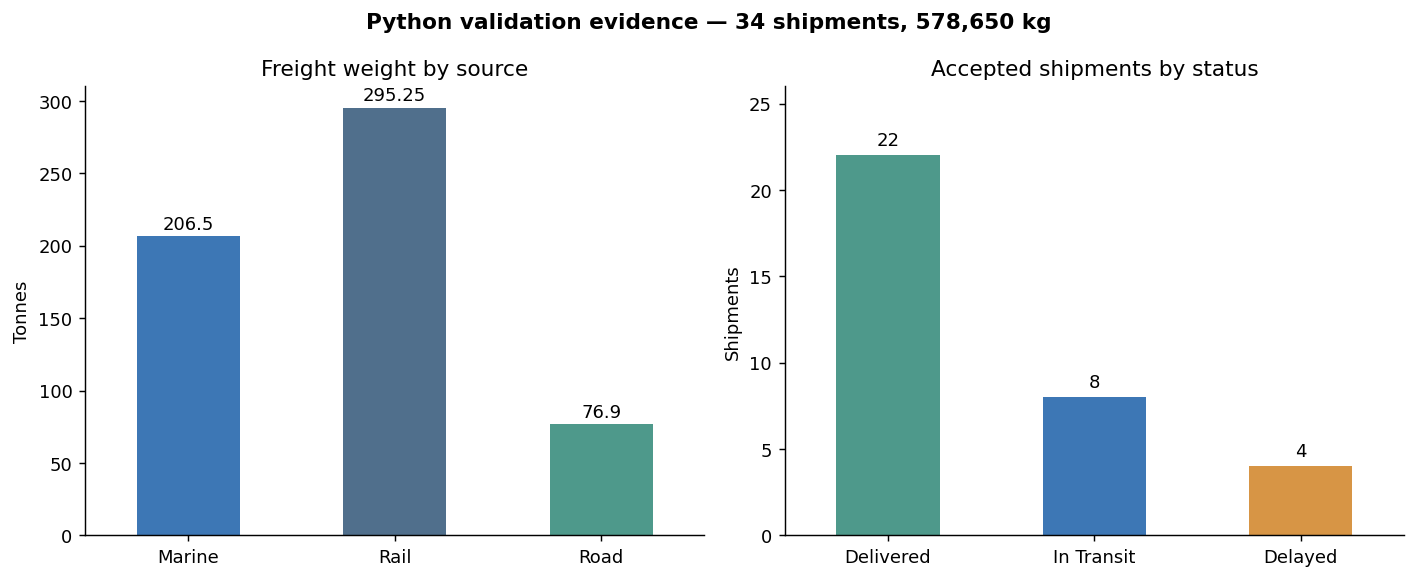

In [10]:
fig, axs=plt.subplots(1,2,figsize=(11,4.5))
mode_t=Shipments.groupby('SourceSystem').WeightKG.sum().reindex(['Marine','Rail','Road'])/1000
mode_t.plot.bar(ax=axs[0],color=['#3d77b5','#506f8c','#4e998b'],rot=0)
axs[0].set(title='Freight weight by source',xlabel='',ylabel='Tonnes')
for i,v in enumerate(mode_t): axs[0].text(i,v+5,f'{v:g}',ha='center')
status=Shipments.Status.value_counts().reindex(['Delivered','In Transit','Delayed'])
status.plot.bar(ax=axs[1],color=['#4e998b','#3d77b5','#d79545'],rot=0)
axs[1].set(title='Accepted shipments by status',xlabel='',ylabel='Shipments',ylim=(0,26))
for i,v in enumerate(status):axs[1].text(i,v+0.6,str(v),ha='center')
fig.suptitle('Python validation evidence — 34 shipments, 578,650 kg',fontweight='bold')
fig.tight_layout();fig.savefig(BASE/'results'/'python_validation.png',bbox_inches='tight');plt.show()


In [11]:
# Authored M scripts for the required Power BI handoff.
for query in ['marine_stg','rail_stg','road_stg','Shipments']:
    m=(BASE/'power_query'/f'{query}.pq').read_text()
    display(Markdown(f'### {query}\n```powerquery\n{m}\n```'))


### marine_stg
```powerquery
let
    Source = Csv.Document(File.Contents(DataFolder & "\marine_shipments.csv"), [Delimiter=",", Encoding=65001, QuoteStyle=QuoteStyle.Csv]),
    Headers = Table.PromoteHeaders(Source, [PromoteAllScalars=true]),
    Renamed = Table.RenameColumns(Headers, {{"Shipment_ID","ShipmentID"},{"Ship_Date","ShipDate"},{"Origin_Port","Origin"},{"Dest_Port","Destination"},{"Weight_KG","WeightKG"},{"Cost_PKR","CostPKR"}}),
    Typed = Table.TransformColumnTypes(Renamed, {{"ShipmentID",type text},{"ShipDate",type date},{"Origin",type text},{"Destination",type text},{"WeightKG",type number},{"CostPKR",Currency.Type},{"Status",type text}}, "en-GB"),
    Cleaned = Table.TransformColumns(Typed, {{"Status",each Text.Proper(Text.Trim(_)),type text},{"Origin",Text.Trim,type text},{"Destination",Text.Trim,type text}}),
    Tagged = Table.AddColumn(Cleaned, "SourceSystem", each "Marine", type text),
    Contract = Table.SelectColumns(Tagged, {"ShipmentID","ShipDate","Origin","Destination","WeightKG","CostPKR","Status","SourceSystem"})
in
    Contract

```

### rail_stg
```powerquery
let
    Source = Excel.Workbook(File.Contents(DataFolder & "\rail_shipments.xlsx"), null, true),
    Raw = Source{[Item="Rail",Kind="Sheet"]}[Data],
    RemovedTopRows = Table.Skip(Raw, 2),
    Headers = Table.PromoteHeaders(RemovedTopRows, [PromoteAllScalars=true]),
    Renamed = Table.RenameColumns(Headers, {{"Consignment No","ShipmentID"},{"Dispatch Date","ShipDate"},{"From Station","Origin"},{"To Station","Destination"},{"Freight Charges (PKR)","CostPKR"}}),
    Typed = Table.TransformColumnTypes(Renamed, {{"ShipmentID",Int64.Type},{"ShipDate",type date},{"Origin",type text},{"Destination",type text},{"Weight (Tons)",type number},{"CostPKR",Currency.Type},{"Status",type text}}, "en-GB"),
    ConvertedWeight = Table.AddColumn(Typed, "WeightKG", each [#"Weight (Tons)"] * 1000, type number),
    RemovedTons = Table.RemoveColumns(ConvertedWeight, {"Weight (Tons)"}),
    PrefixedIDs = Table.TransformColumns(RemovedTons, {{"ShipmentID",each "RL-" & Text.From(_, "en-GB"),type text}}),
    Cleaned = Table.TransformColumns(PrefixedIDs, {{"Status",each Text.Proper(Text.Trim(_)),type text},{"Origin",Text.Trim,type text},{"Destination",Text.Trim,type text}}),
    Tagged = Table.AddColumn(Cleaned, "SourceSystem", each "Rail", type text),
    Contract = Table.SelectColumns(Tagged, {"ShipmentID","ShipDate","Origin","Destination","WeightKG","CostPKR","Status","SourceSystem"})
in
    Contract

```

### road_stg
```powerquery
let
    Source = Csv.Document(File.Contents(DataFolder & "\road_shipments.csv"), [Delimiter=",", Encoding=65001, QuoteStyle=QuoteStyle.Csv]),
    Headers = Table.PromoteHeaders(Source, [PromoteAllScalars=true]),
    Renamed = Table.RenameColumns(Headers, {{"trip_id","ShipmentID"},{"trip_date","ShipDate"},{"from_city","Origin"},{"to_city","Destination"},{"weight_kg","WeightKG"},{"cost_pkr","CostPKR"},{"status","Status"}}),
    Indexed = Table.AddIndexColumn(Renamed, "RawRow", 2, 1, Int64.Type),
    UpperIDs = Table.TransformColumns(Indexed, {{"ShipmentID",each if _ = null then "" else Text.Upper(Text.Trim(_)),type text}}),
    RemovedBlankRows = Table.SelectRows(UpperIDs, each List.AnyTrue(List.Transform(Record.FieldValues(Record.RemoveFields(_, {"RawRow"})), each _ <> null and Text.Trim(Text.From(_)) <> ""))),
    RemovedTotal = Table.SelectRows(RemovedBlankRows, each [ShipmentID] <> "TOTAL"),
    // Buffer the sorted rows so the first identical RD-505 occurrence is retained.
    Buffered = Table.Buffer(Table.Sort(RemovedTotal, {{"RawRow",Order.Ascending}})),
    RemovedDuplicates = Table.Distinct(Buffered, {"ShipmentID"}),
    Typed = Table.TransformColumnTypes(RemovedDuplicates, {{"ShipmentID",type text},{"ShipDate",type date},{"Origin",type text},{"Destination",type text},{"WeightKG",type number},{"CostPKR",Currency.Type},{"Status",type text}}, "en-GB"),
    Cleaned = Table.TransformColumns(Typed, {{"Status",each Text.Proper(Text.Trim(_)),type text},{"Origin",Text.Trim,type text},{"Destination",Text.Trim,type text}}),
    Tagged = Table.AddColumn(Cleaned, "SourceSystem", each "Road", type text),
    Contract = Table.SelectColumns(Tagged, {"ShipmentID","ShipDate","Origin","Destination","WeightKG","CostPKR","Status","SourceSystem"})
in
    Contract

```

### Shipments
```powerquery
let
    Appended = Table.Combine({marine_stg,rail_stg,road_stg}),
    Contract = Table.SelectColumns(Appended, {"ShipmentID","ShipDate","Origin","Destination","WeightKG","CostPKR","Status","SourceSystem"}),
    Typed = Table.TransformColumnTypes(Contract, {{"ShipmentID",type text},{"ShipDate",type date},{"Origin",type text},{"Destination",type text},{"WeightKG",type number},{"CostPKR",Currency.Type},{"Status",type text},{"SourceSystem",type text}}),
    Keys = Table.Column(Typed,"ShipmentID"),
    Dates = Table.Column(Typed,"ShipDate"),
    Weights = Table.Column(Typed,"WeightKG"),
    Validated = if Table.RowCount(Typed) = 34 and List.Sum(Weights) = 578650 and List.NonNullCount(Keys) = 34 and not List.Contains(Keys, "") and List.Count(List.Distinct(Keys)) = 34 and List.NonNullCount(Dates) = 34 and List.NonNullCount(Weights) = 34 and List.Count(List.Distinct(Table.Column(Typed,"Status"))) = 3
                then Typed else error "Shipment validation failed: check sources, exclusions, units and dates."
in
    Validated

```

## Task 5 — Latency, drift, lineage and ownership

| Consumer | Freshness | Reason |
|---|---|---|
| Dispatcher avoiding blocked motorway | Near-real-time, event updates within seconds to two minutes | Routing decisions need current positions and incident events |
| CFO monthly cost-per-tonne | Daily batch | Latest reconciled daily totals are sufficient for monthly analysis |
| Online consignment tracking | Near-real-time, about two minutes | Customers need recent accepted dispatch/delivery events |
| Quarterly board review | Weekly, then final period-close snapshot | Decisions depend on reconciled trends rather than second-by-second movement |

Always real-time adds streaming/compute/monitoring cost and increases operational coupling: partial, late or conflicting events require ordering and deduplication logic. A frequently changing unclosed total also increases reconciliation work without improving a quarterly decision.

### Schema drift in the supplied M

| Rail change | Exact next-refresh behaviour | Detection/control |
|---|---|---|
| Adds Wagon_Type | Continues; final explicit eight-column selection drops the unused extra field | Compare actual header set to an approved schema and flag additions before they silently disappear |
| Renames Freight Charges (PKR) to Charges_PKR | Fails at RenameColumns with missing required old column; no MissingField.Ignore is used | Required-column contract test on promoted headers, alert owner and approve a versioned mapping |

This behaviour depends on the actual authored code. A pipeline that appends every field without an explicit projection would instead introduce Wagon_Type into the model and violate the eight-column contract. Source owners must communicate planned changes before refreshing a production model.

### Metric lineage and investigation

Three unchanged sources → source-specific staging (marine locale, rail ×1,000, road blank/TOTAL/duplicate exclusions) → append eight common columns → accepted Shipments → SUM(WeightKG) card = 578,650 → tonne display = 578.65.

If the CFO thinks the number is too low, first verify source completeness, reporting period and rail units against raw exports. Second inspect staged conversion and the exact three rejection records, checking whether a legitimate shipment was rejected. Third check append coverage, report date/status filters and measure definition; do not change a control value to fit a preferred answer.

| Responsibility | Owner | Main tier |
|---|---|---|
| Shipment star schema | Data architect | Storage and presentation boundary |
| Power Query maintenance | ETL/data engineer | Staging |
| Official Delivered definition | Business/data steward | Cross-tier semantic governance |
| Morning operations dashboard | BI developer | Presentation |
| Rail export contract | Source system owner | Source interface into staging |

The data engineer owns staging and its rejection/quality logs; without that owner the rail unit and road junk reach reports. The architect owns integrated storage and shared grain/keys; without that owner three inconsistent marts persist. The BI developer owns presentation with steward-approved measures; without that ownership report-specific filters or hidden conversions recreate the stovepipe totals. Stewardship is needed across all three tiers for business definitions.

A freight analyst must validate their own output because a precise-looking number can still have the wrong unit or grain. If Finance's 283,695.25 kg were accepted, PakFreight would understate volume by 294,954.75 kg; cost-per-tonne would be inflated and could lead to a wrong rail pricing or capacity decision. Recorded controls protect decisions and make later correction possible.

**Inherited dashboard:** Record its measure, filters, time period and last successful refresh before changing it. Follow lineage back through the model and append to immutable exports, independently recompute the figure and compare accepted/rejected rows. Check whether source event time and refresh latency explain the mismatch, then compare actual schemas/units to the contracts and review failed or skipped transformations. Resolve the cause with the relevant owner, rerun controls and document the corrected lineage before republishing.


In [12]:
# Demonstrate schema drift detection without modifying an export.
rail_extra=raw['Rail'].copy();rail_extra['Wagon_Type']='Example only'
rail_renamed=raw['Rail'].rename(columns={'Freight Charges (PKR)':'Charges_PKR'})
def schema_difference(frame,mode):
    actual=set(frame.columns)-{'_SourceFile','_RawRow'}
    required=set(MAPPING[mode])
    return {'Missing required': sorted(required-actual), 'Unexpected': sorted(actual-required)}
display(pd.DataFrame([{'Change':'Add Wagon_Type',**schema_difference(rail_extra,'Rail')},
                      {'Change':'Rename charge field',**schema_difference(rail_renamed,'Rail')}]))
print('Python uses a strict header contract and flags both changes. Supplied M drops the addition and fails the required rename.')


,Change,Missing required,Unexpected
0,Add Wagon_Type,[],[Wagon_Type]
1,Rename charge field,[Freight Charges (PKR)],[Charges_PKR]


Python uses a strict header contract and flags both changes. Supplied M drops the addition and fails the required rename.


### Deliverables
The results folder contains accepted Shipments, raw-row lineage, exclusion reasons, source hashes and Python diagrams. The completed activity workbook uses live formulas with independent reconciliation checks. Power BI setup steps remain in `POWER_BI_SETUP.md`; genuine PBIX/UI evidence must be added in Power BI Desktop to meet the original rubric.